# CMPE 257 Project: Mapping Rice Water-Management Practices in Punjab

## 1. Setup and load data

In [ ]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def load_all():
    files = sorted(glob.glob("data/features/**/*.parquet", recursive=True))
    if not files:
        raise FileNotFoundError("no parquet files found")
    # Key = "<date window>/<feature set>", e.g. "05-01_12-15_f10d/train_HC"
    return {os.path.relpath(f, "data/features").replace(".parquet", ""): pd.read_parquet(f)
            for f in files}

try:
    datasets = load_all()
except Exception as e:
    print("Load failed, downloading the repo fresh:", type(e).__name__)
    %cd /content
    !rm -rf rice-irrigation-mapping-s1s2
    !git clone https://github.com/microsoft/rice-irrigation-mapping-s1s2.git
    %cd rice-irrigation-mapping-s1s2
    datasets = load_all()

for name, d in datasets.items():
    print(f"{name:35s} {d.shape}")

Load failed, downloading the repo fresh: FileNotFoundError
/content
Cloning into 'rice-irrigation-mapping-s1s2'...
remote: Enumerating objects: 122, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 122 (delta 12), reused 4 (delta 1), pack-reused 81 (from 1)
Receiving objects: 100% (122/122), 126.03 MiB | 15.26 MiB/s, done.
Resolving deltas: 100% (17/17), done.
Updating files: 100% (77/77), done.
/content/rice-irrigation-mapping-s1s2
05-01_12-15_f10d/train_HC           (1283, 63)
05-01_12-15_f10d/train_HC_P         (1283, 5823)
05-01_12-15_f10d/train_HC_P_SE      (1283, 5887)
05-01_12-15_f10d/train_HC_SE        (1283, 127)
06-01_09-05_f4d/train_HC            (1283, 63)
06-01_09-05_f4d/train_HC_P          (1283, 6335)
06-01_09-05_f4d/train_HC_P_SE       (1283, 6399)
06-01_09-05_f4d/train_HC_SE         (1283, 127)


Two date windows (`05-01_12-15_f10d`, `06-01_09-05_f4d`), each with feature sets
**HC** (handcrafted radar features), **SE** (Google Satellite Embeddings) and **P** (Presto embeddings).
This notebook uses **HC** and **HC_SE**, the two smaller sets.

## 2. Data cleaning

In [ ]:
df = datasets["05-01_12-15_f10d/train_HC"]

print("Class counts:\n", df["label"].value_counts(), "\n")
print("'Class' column identical to 'label':", (df["label"] == df["Class"]).all())

feats = df.drop(columns=["label", "Class"])
print("Non-numeric feature columns:", feats.select_dtypes(exclude="number").columns.tolist())
print("Infinite values:", int(np.isinf(feats).sum().sum()))
print("Constant columns:", feats.columns[feats.nunique() <= 1].tolist())

nan_cols = feats.isna().sum()
print("\nColumns with missing values:\n", nan_cols[nan_cols > 0])
print("Rows with missing values:", int(feats.isna().any(axis=1).sum()))
print("\nDuplicate rows (HC features):", int(feats.duplicated().sum()))

Class counts:
 label
AWD    452
DSR    420
PTR    411
Name: count, dtype: int64 

'Class' column identical to 'label': True
Non-numeric feature columns: []
Infinite values: 0
Constant columns: []

Columns with missing values:
 ASCENDING_ratio_gaussian_a     2
ASCENDING_ratio_gaussian_b     2
ASCENDING_ratio_gaussian_c     2
ASCENDING_ratio_gaussian_r2    2
dtype: int64
Rows with missing values: 2

Duplicate rows (HC features): 34


**Cleaning decisions**

- `Class` is an exact copy of `label`, so we drop it (otherwise it would leak the answer).
- Only 4 columns (`ASCENDING_ratio_gaussian_*`, curve-fit parameters) have missing values, in 1 to 2 rows.
  We keep those rows and fill the gaps with the **column median**.
- No infinite values or constant columns in HC, but the function below checks for both anyway.
- 34 rows have HC features identical to another row (same label). Most of these are *different fields*
  (they differ in the SE features), so we keep all 1,283 rows to match the paper.

In [ ]:
def clean(df):
    """Return numeric feature table X (no NaN) and label y."""
    y = df["label"]
    X = df.drop(columns=["label", "Class"]).select_dtypes("number")
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.loc[:, X.nunique() > 1]                       # drop constant columns
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X),
                     columns=X.columns, index=X.index)  # fill NaN with median
    return X, y

X, y = clean(datasets["05-01_12-15_f10d/train_HC"])
print(X.shape, "| missing values left:", int(X.isna().sum().sum()))

(1283, 61) | missing values left: 0


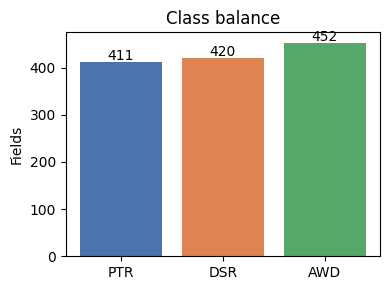

VV_ASCENDING_mean_spline_num_crests       8.8
VV_ASCENDING_mean_spline_crest_days_3     8.4
VH_ASCENDING_mean_spline_crest_days_3     8.4
VV_ASCENDING_mean_spline_crest_days_2     8.0
VV_ASCENDING_mean_spline_num_troughs      7.3
VV_ASCENDING_mean_spline_trough_days_2    6.7
dtype: float64


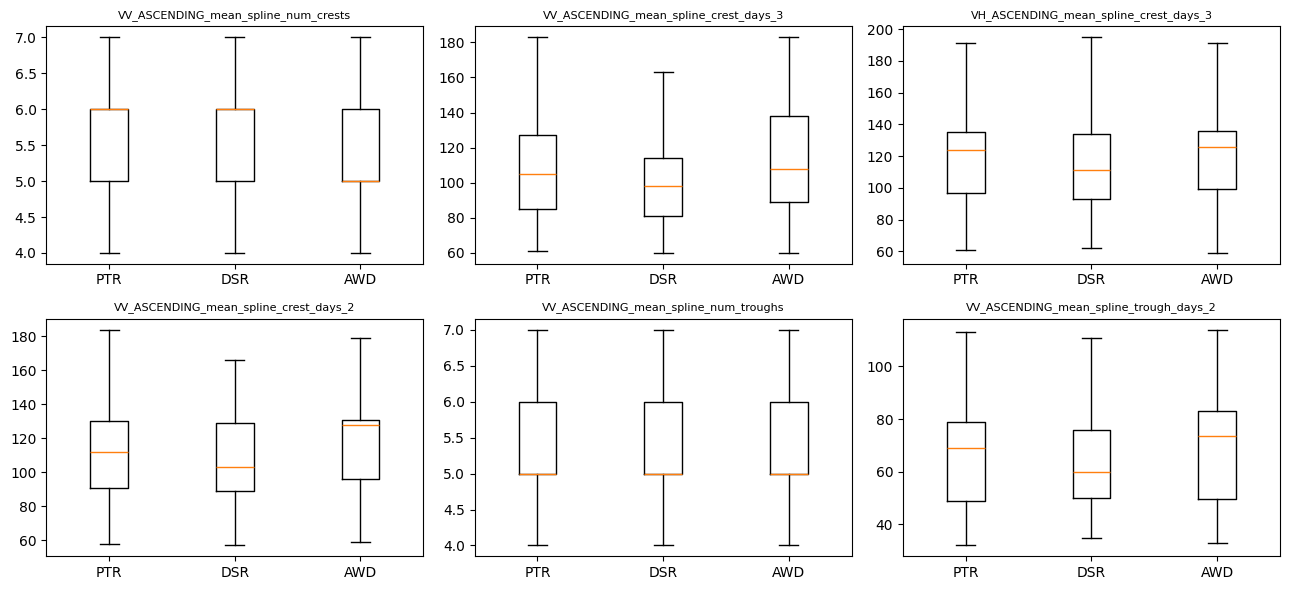

In [ ]:
from sklearn.feature_selection import f_classif

X, y = clean(datasets["05-01_12-15_f10d/train_HC"])
order = ["PTR", "DSR", "AWD"]

# Class balance
counts = y.value_counts()[order]
plt.figure(figsize=(4, 3))
plt.bar(order, counts.values, color=["#4c72b0", "#dd8452", "#55a868"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.ylabel("Fields"); plt.title("Class balance"); plt.tight_layout(); plt.show()

# Rank features by how well they separate the 3 classes on their own (ANOVA F-score)
F, _ = f_classif(X, y)
top = pd.Series(F, index=X.columns).sort_values(ascending=False)
top = top[[c for c in top.index if not c.endswith(("trough_days_3", "crest_days_1"))]]
print(top.head(6).round(1))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), top.index[:6]):
    ax.boxplot([X.loc[y == c, col] for c in order], showfliers=False)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(order)
    ax.set_title(col, fontsize=8)
plt.tight_layout(); plt.show()

The three classes are within 10% of each other, so accuracy and weighted F1 are both meaningful.

There appears to be heavily overlap for all six figures, meaning that there is no easily separable feature. That makes multivariate models a good fit for this dataset.

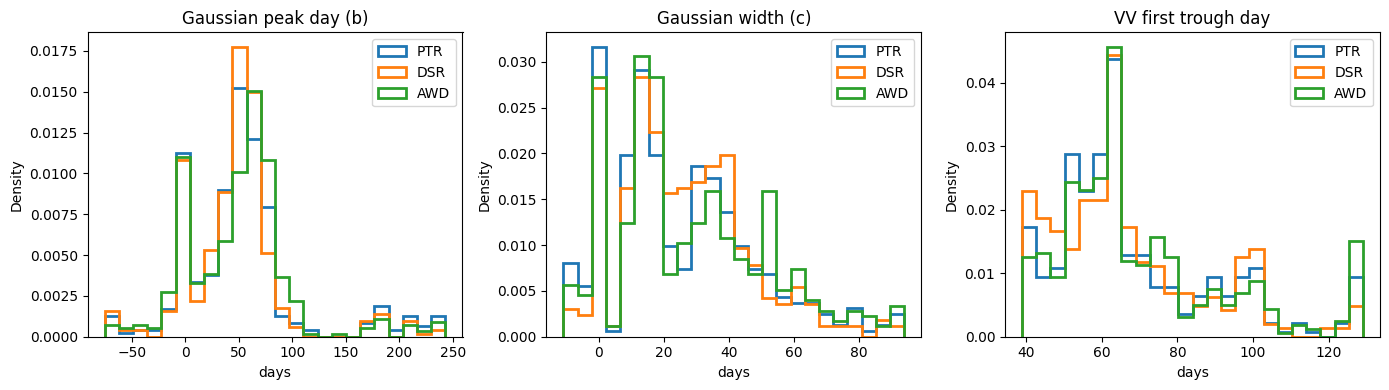

       ASCENDING_ratio_gaussian_b  ASCENDING_ratio_gaussian_c
label                                                        
AWD                          56.2                        22.0
DSR                          48.9                        23.6
PTR                          50.1                        19.5


In [ ]:
raw = datasets["05-01_12-15_f10d/train_HC"]
panels = [("ASCENDING_ratio_gaussian_b", "Gaussian peak day (b)"),
          ("ASCENDING_ratio_gaussian_c", "Gaussian width (c)"),
          ("VV_ASCENDING_mean_spline_trough_days_1", "VV first trough day")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, title) in zip(axes, panels):
    v = raw[col].astype(float)
    bins = np.linspace(v.quantile(0.05), v.quantile(0.95), 25)   # trim extreme tails
    for c in order:
        ax.hist(v[raw["label"] == c].dropna(), bins=bins, histtype="step",
                density=True, linewidth=2, label=c)
    ax.set(title=title, xlabel="days", ylabel="Density"); ax.legend()
plt.tight_layout(); plt.show()

print(raw.groupby("label")[[p[0] for p in panels[:2]]].median().round(1))

PCA helps most when features are correlated

In [ ]:
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)

print("Feature pairs with |r| > 0.9:", int((pairs > 0.9).sum()), "of", len(pairs))
print("Feature pairs with |r| > 0.7:", int((pairs > 0.7).sum()))
print("\nMost correlated pairs:")
print(pairs.head(5).round(3))

Feature pairs with |r| > 0.9: 6 of 1830
Feature pairs with |r| > 0.7: 44

Most correlated pairs:
min_ASCENDING_spline_ratio                 std_ASCENDING_spline_ratio       0.975
max_VH_ASCENDING_mean_spline               std_VH_ASCENDING_mean_spline     0.936
min_ASCENDING_spline_ratio                 mean_ASCENDING_spline_ratio      0.932
VH_ASCENDING_mean_spline_troughs_values_1  mean_VH_ASCENDING_mean_spline    0.913
ASCENDING_ratio_gaussian_b                 ASCENDING_ratio_gaussian_c       0.913
dtype: float64


## Correlation Matrix Heatmap

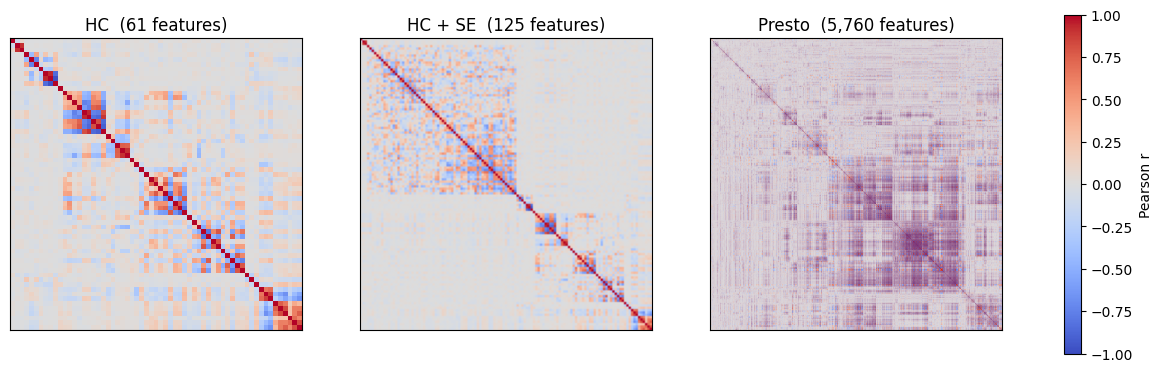

,dataset,n_features,|r| > 0.9,|r| > 0.7,mean |r|
0,HC,61,6,44,0.116
1,HC + SE,125,6,52,0.103
2,Presto,5760,81442,1065582,0.311


In [ ]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

window = "05-01_12-15_f10d"          # or "06-01_09-05_f4d"

def ordered_corr(M):
    """Correlation matrix of the columns of M, features reordered so correlated ones sit together."""
    c = np.nan_to_num(np.corrcoef(M, rowvar=False))
    dist = np.clip(1 - np.abs(c), 0, None)
    order = leaves_list(linkage(squareform(dist, checks=False), method="average"))
    return c[np.ix_(order, order)]

presto_df = datasets[f"{window}/train_HC_P"]
presto = presto_df[[c for c in presto_df.columns if c.startswith(("time_", "location_"))]].astype(float)

blocks = {"HC": clean(datasets[f"{window}/train_HC"])[0],
          "HC + SE": clean(datasets[f"{window}/train_HC_SE"])[0],
          "Presto": presto}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
rows = []
for ax, (title, M) in zip(axes, blocks.items()):
    c = ordered_corr(M.values)
    im = ax.imshow(c, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{title}  ({M.shape[1]:,} features)")
    r = np.abs(c[np.triu_indices(len(c), 1)])
    rows.append({"dataset": title, "n_features": M.shape[1], "|r| > 0.9": int((r > 0.9).sum()),
                 "|r| > 0.7": int((r > 0.7).sum()), "mean |r|": round(r.mean(), 3)})
fig.colorbar(im, ax=axes, shrink=0.8, label="Pearson r")
plt.show()
pd.DataFrame(rows)

## 3. PCA

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X, y = clean(datasets["05-01_12-15_f10d/train_HC"])
X_std = StandardScaler().fit_transform(X)
pca = PCA().fit(X_std)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
k90 = int(np.searchsorted(cumulative, 0.90) + 1)
k95 = int(np.searchsorted(cumulative, 0.95) + 1)

print(f"{X.shape[1]} features")
print(f"PC1 explains {explained[0]:.1%}, PC2 {explained[1]:.1%}, PC3 {explained[2]:.1%}")
print(f"Components needed for 90% variance: {k90}, for 95%: {k95}")

61 features
PC1 explains 14.0%, PC2 11.0%, PC3 7.3%
Components needed for 90% variance: 28, for 95%: 35


## 4. Components Needed

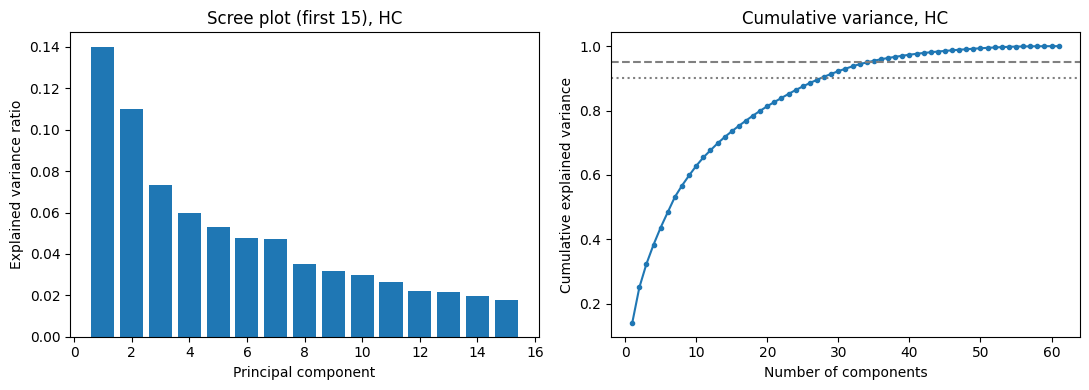

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].bar(range(1, 16), explained[:15])
ax[0].set(xlabel="Principal component", ylabel="Explained variance ratio", title="Scree plot (first 15), HC")

ax[1].plot(range(1, len(cumulative) + 1), cumulative, marker="o", ms=3)
ax[1].axhline(0.95, ls="--", c="gray"); ax[1].axhline(0.90, ls=":", c="gray")
ax[1].set(xlabel="Number of components", ylabel="Cumulative explained variance", title="Cumulative variance, HC")

plt.tight_layout(); plt.show()

Same analysis for HC and HC+SE in both date windows:

In [ ]:
rows = []
curves = {}
for name, d in datasets.items():
    if not name.endswith(("train_HC", "train_HC_SE")):
        continue
    Xs, _ = clean(d)
    ratio = PCA().fit(StandardScaler().fit_transform(Xs)).explained_variance_ratio_
    cum = np.cumsum(ratio)
    curves[name] = cum
    rows.append({"dataset": name, "n_features": Xs.shape[1],
                 "PC1 share": f"{ratio[0]:.1%}",
                 "k for 90%": int(np.searchsorted(cum, 0.90) + 1),
                 "k for 95%": int(np.searchsorted(cum, 0.95) + 1)})
pd.DataFrame(rows)

,dataset,n_features,PC1 share,k for 90%,k for 95%
0,05-01_12-15_f10d/train_HC,61,14.0%,28,35
1,05-01_12-15_f10d/train_HC_SE,125,10.9%,45,59
2,06-01_09-05_f4d/train_HC,61,12.4%,27,35
3,06-01_09-05_f4d/train_HC_SE,125,10.8%,45,60


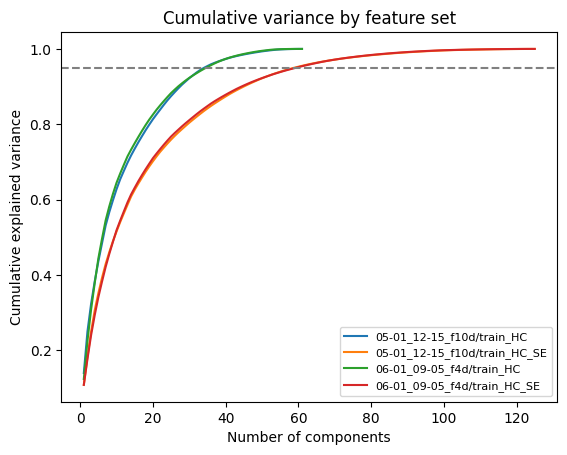

In [ ]:
for name, cum in curves.items():
    plt.plot(range(1, len(cum) + 1), cum, label=name)
plt.axhline(0.95, ls="--", c="gray")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("Cumulative variance by feature set"); plt.legend(fontsize=8); plt.show()

**How to read it:** the closer the curve is to the top-left, the more redundant the features. If 95% of the variance
needs, say, 35 of 61 components, PCA compresses HC by roughly 40%, but there is no dramatic elbow. Adding the 64 SE
features adds a lot of new variance (more components needed), so SE is not just a copy of HC.

In [ ]:
rows = []
for window in ["05-01_12-15_f10d", "06-01_09-05_f4d"]:
    d = datasets[f"{window}/train_HC_P_SE"]
    se = [c for c in d.columns if c.startswith("sat_emb_")]
    pr = [c for c in d.columns if c.startswith(("time_", "location_"))]
    hc = [c for c in d.columns if c not in se + pr + ["label", "Class"]
          and pd.api.types.is_numeric_dtype(d[c])]
    families = {"HC": d[hc], "SE": d[se], "Presto (flattened)": d[pr].astype(float)}

    for name, M in families.items():
        M = M.replace([np.inf, -np.inf], np.nan)
        M = M.loc[:, M.nunique() > 1]
        Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(M))
        cum = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
        rows.append({"window": window, "family": name,
                     "features": M.shape[1], "components_95": int(np.searchsorted(cum, 0.95) + 1)})

pd.DataFrame(rows)

,window,family,features,components_95
0,05-01_12-15_f10d,HC,61,35
1,05-01_12-15_f10d,SE,64,26
2,05-01_12-15_f10d,Presto (flattened),5760,38
3,06-01_09-05_f4d,HC,61,35
4,06-01_09-05_f4d,SE,64,26
5,06-01_09-05_f4d,Presto (flattened),6272,21


## 5. Project to 2D and look at the components

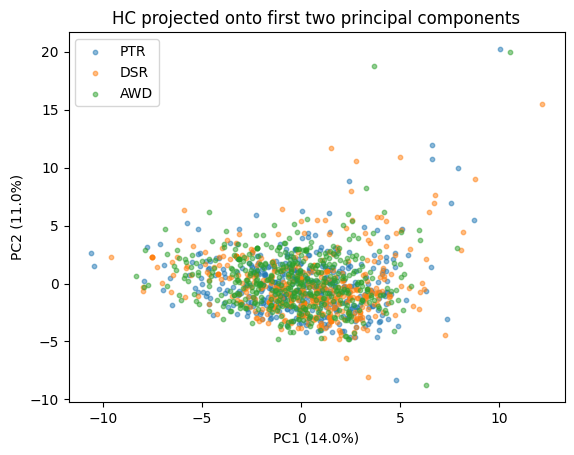

PC1 top features by |loading|:
VH_ASCENDING_mean_spline_num_troughs      0.231
VH_ASCENDING_mean_spline_crest_days_3     0.230
VH_ASCENDING_mean_spline_crest_days_2     0.222
VH_ASCENDING_mean_spline_trough_days_2    0.214
VH_ASCENDING_mean_spline_num_crests       0.214 

PC2 top features by |loading|:
mean_VH_ASCENDING_mean_spline                0.305
std_VH_ASCENDING_mean_spline                 0.292
VH_ASCENDING_mean_spline_troughs_values_1    0.290
max_VH_ASCENDING_mean_spline                 0.274
VH_ASCENDING_mean_spline_crests_values_2     0.260 

PC3 top features by |loading|:
ASCENDING_spline_ratio_crest_days_3     0.308
ASCENDING_spline_ratio_crest_days_2     0.303
ASCENDING_spline_ratio_trough_days_2    0.299
ASCENDING_spline_ratio_trough_days_1    0.291
ASCENDING_spline_ratio_num_troughs      0.263 



In [ ]:
Z = pca.transform(X_std)[:, :2]

for cls in y.unique():
    m = (y == cls).values
    plt.scatter(Z[m, 0], Z[m, 1], s=10, alpha=0.5, label=cls)
plt.xlabel(f"PC1 ({explained[0]:.1%})"); plt.ylabel(f"PC2 ({explained[1]:.1%})")
plt.title("HC projected onto first two principal components"); plt.legend(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
for pc in ["PC1", "PC2", "PC3"]:
    print(pc, "top features by |loading|:")
    print(loadings[pc].abs().sort_values(ascending=False).head(5).round(3).to_string(), "\n")

In [ ]:
# Which original features contribute most to each component? (loadings = entries of components_)
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
for pc in ["PC1", "PC2", "PC3"]:
    print(pc, "top features by |loading|:")
    print(loadings[pc].abs().sort_values(ascending=False).head(5).round(3).to_string(), "\n")

PC1 top features by |loading|:
VH_ASCENDING_mean_spline_num_troughs      0.231
VH_ASCENDING_mean_spline_crest_days_3     0.230
VH_ASCENDING_mean_spline_crest_days_2     0.222
VH_ASCENDING_mean_spline_trough_days_2    0.214
VH_ASCENDING_mean_spline_num_crests       0.214 

PC2 top features by |loading|:
mean_VH_ASCENDING_mean_spline                0.305
std_VH_ASCENDING_mean_spline                 0.292
VH_ASCENDING_mean_spline_troughs_values_1    0.290
max_VH_ASCENDING_mean_spline                 0.274
VH_ASCENDING_mean_spline_crests_values_2     0.260 

PC3 top features by |loading|:
ASCENDING_spline_ratio_crest_days_3     0.308
ASCENDING_spline_ratio_crest_days_2     0.303
ASCENDING_spline_ratio_trough_days_2    0.299
ASCENDING_spline_ratio_trough_days_1    0.291
ASCENDING_spline_ratio_num_troughs      0.263 



## 6. Presto embeddings

The Presto sets (`train_HC_P`) contain a pretrained model's embedding of each field: a 128-number vector per time step
(`time_<step>_<dim>`) plus one 128-number vector for the field's location (`location_<step>_<dim>`).

- window `05-01_12-15_f10d`: 44 time steps + location = 45 x 128 = **5,760** columns
- window `06-01_09-05_f4d`: 48 time steps + location = 49 x 128 = **6,272** columns

That is far more columns than the 1,283 fields, so PCA can return at most **1,283** components, and compression is the whole point.
Here we use scikit-learn's `PCA`, because the manual covariance matrix would be 5,760 x 5,760.
We analyze the embedding block only (not the HC columns), so HC does not get drowned out by thousands of embedding columns.

In [ ]:
from sklearn.preprocessing import StandardScaler

d = datasets["05-01_12-15_f10d/train_HC_P"]
emb = d[[c for c in d.columns if c.startswith(("time_", "location_"))]]
print("Presto block:", emb.shape)
print("Missing values:", int(emb.isna().sum().sum()), "| constant columns:", int((emb.nunique() <= 1).sum()))

Presto block: (1283, 5760)
Missing values: 0 | constant columns: 0


In [ ]:
import re

d = datasets["06-01_09-05_f4d/train_HC_P"]
tc = sorted([c for c in d.columns if c.startswith("time_")],
            key=lambda c: tuple(map(int, re.findall(r"\d+", c))))   # order by (step, dim)
T = len(tc) // 128
E = d[tc].astype(float).values.reshape(len(d), T, 128)             # (fields, steps, 128)

S = E.reshape(-1, 128)                                              # stack all steps
ratio = PCA().fit(StandardScaler().fit_transform(S)).explained_variance_ratio_
cum = np.cumsum(ratio)
print(f"{T} steps x 128 dims -> k for 90%: {np.searchsorted(cum, .90) + 1}, 95%: {np.searchsorted(cum, .95) + 1}")

48 steps x 128 dims -> k for 90%: 9, 95%: 13


## 7. Setup and load tools

Install and import the packages needed for training

In [ ]:
import subprocess
import sys

subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "scikit-learn>=1.5,<2",
        "lightgbm>=4.5,<5",
        "xgboost>=2.1,<4",
        "catboost>=1.2.7,<2",
        "pyarrow>=16",
    ])

0

In [ ]:
from pathlib import Path
import json
import joblib
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, recall_score, make_scorer
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

## 8. Choose the task and features

Choose one prediction task: **DSR**, **AWD**, or all three classes (**ALL**).

Choose **HC_SE** (handcrafted + AlphaEarth, the paper's 125-feature set) or **HC_PCA64_SE**, which also adds
Presto embeddings compressed to 64 PCA components. The paper does not report this second combination.

For the full results table, run sections 8–12 once per task and feature set (6 runs). Each run saves to its own
folder, and the last cell of section 12 combines all finished runs.

`CV_SPLITS` × `CV_REPEATS` is the number of validation folds used to tune and compare the models.

In [ ]:
TASK = "DSR"  # "DSR", "AWD", or "ALL"
FEATURE_SET = "HC_PCA64_SE"  # "HC_SE" or "HC_PCA64_SE"
RUN_NAME = "simple_run_001"
SAVE_TO_DRIVE = False
EVALUATE_TEST = True  # set to False while still changing models
SEED = 42
THREADS = 2
CV_SPLITS = 5   # grouped validation folds per repeat
CV_REPEATS = 2  # repeats with a different shuffle (5 x 2 = 10 folds)

assert TASK in ["DSR", "AWD", "ALL"]
assert FEATURE_SET in ["HC_SE", "HC_PCA64_SE"]
assert "datasets" in globals()
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_BASE = Path("/content/drive/MyDrive/CMPE257/simple_results")
else:
    RESULTS_BASE = Path.cwd() / "simple_results"

OUT = RESULTS_BASE / RUN_NAME / TASK / FEATURE_SET
OUT.mkdir(parents=True, exist_ok=True)
print("Task:", TASK, "| Features:", FEATURE_SET)
print("Results folder:", OUT)

Task: DSR | Features: HC_PCA64_SE
Results folder: /content/rice-irrigation-mapping-s1s2/simple_results/simple_run_001/DSR/HC_PCA64_SE


In [ ]:
WINDOWS = {"DSR": "06-01_09-05_f4d",
           "AWD": "05-01_12-15_f10d",
           "ALL": "06-01_09-05_f4d",}
LABEL_MAPS = {"DSR": {"AWD": 0, "PTR": 0, "DSR": 1},
              "AWD": {"AWD": 1, "PTR": 0, "DSR": 0},
              "ALL": {"AWD": 0, "PTR": 1, "DSR": 2},}
POSITIVE_NAME = {"DSR": "DSR", "AWD": "AWD", "ALL": None}[TASK]  # class coded as 1 in the binary tasks

raw = datasets[f"{WINDOWS[TASK]}/train_HC_P_SE"]
X = raw.drop(columns=["label", "Class"]).replace([np.inf, -np.inf], np.nan)
y = raw["label"].map(LABEL_MAPS[TASK])
assert y.notna().all(), "Unexpected class label."

hc_columns = X.columns[~X.columns.str.startswith(("time_", "location_", "sat_emb_"))]
ae_columns = X.columns[X.columns.str.startswith("sat_emb_")]
presto_columns = X.columns[X.columns.str.startswith(("time_", "location_"))]
print("Rows:", len(X), "| Class counts:", y.value_counts().to_dict())

Rows: 1283 | Class counts: {0: 863, 1: 420}


## 9. Prepare and split the data

About 10% of the fields are held out as the test set, the same 90:10 ratio as the paper. Fields with identical
handcrafted features are linked into groups, and a group never spans two partitions. The paper used a plain
stratified random split, so this setup is stricter. The split depends only on the 3-class label and the groups,
so **every task and feature set uses the same test fields**.

The development rows are split into `CV_SPLITS` grouped folds, repeated `CV_REPEATS` times with different
shuffles. Every model is tuned and compared on these same folds. Missing-value filling and the optional Presto PCA
are fitted inside each training fold, so validation and test rows never influence them.

In [ ]:
hc_short = datasets["06-01_09-05_f4d/train_HC"]
hc_long = datasets["05-01_12-15_f10d/train_HC"]
assert hc_short.index.equals(hc_long.index)
assert hc_short["label"].equals(hc_long["label"])
assert raw[hc_short.columns].equals(datasets[f"{WINDOWS[TASK]}/train_HC"])

# Link each row to the first identical HC row in each window.
positions = np.arange(len(X))
short_keys = pd.util.hash_pandas_object(
    hc_short.drop(columns=["label", "Class"]).replace([np.inf, -np.inf], np.nan),
    index=False,
)
long_keys = pd.util.hash_pandas_object(
    hc_long.drop(columns=["label", "Class"]).replace([np.inf, -np.inf], np.nan),
    index=False,
)
short_first = pd.Series(positions).groupby(short_keys.to_numpy()).transform("min")
long_first = pd.Series(positions).groupby(long_keys.to_numpy()).transform("min")
links = coo_matrix(
    (np.ones(2 * len(X)), (np.tile(positions, 2), np.concatenate([short_first, long_first])),),
    shape=(len(X), len(X)),
)
_, groups = connected_components(links, directed=False)

splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
train_rows, test_rows = next(splitter.split(X, raw["label"], groups))
X_train, X_test = X.iloc[train_rows], X.iloc[test_rows]
y_train, y_test = y.iloc[train_rows], y.iloc[test_rows]
dev_groups = groups[train_rows]

# Repeated grouped folds on the development rows, shared by every model.
cv_folds = []
for repeat in range(CV_REPEATS):
    fold_splitter = StratifiedGroupKFold(n_splits=CV_SPLITS, shuffle=True,
                                         random_state=SEED + 1 + repeat)
    cv_folds += list(fold_splitter.split(X_train, raw["label"].iloc[train_rows], dev_groups))

assert set(groups[train_rows]).isdisjoint(groups[test_rows])
assert all(set(dev_groups[fit]).isdisjoint(dev_groups[val]) for fit, val in cv_folds)
print("Development rows:", len(X_train), "| Test rows:", len(X_test))
print("Validation folds:", len(cv_folds),
      "| validation rows per fold ≈", round(np.mean([len(val) for _, val in cv_folds])))

Development rows: 1160 | Test rows: 123
Validation folds: 10 | validation rows per fold ≈ 232


In [ ]:
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
preprocessor = ColumnTransformer(
    [("hc_ae", imputer, list(hc_columns) + list(ae_columns))])

if FEATURE_SET == "HC_PCA64_SE":
    presto_pipeline = Pipeline(
        [("impute", clone(imputer)),
         ("scale", StandardScaler()),
         ("pca", PCA(n_components=64, svd_solver="randomized", random_state=SEED)),
        ])
    preprocessor = ColumnTransformer(
        [("hc_ae", clone(imputer), list(hc_columns) + list(ae_columns)),
         ("presto", presto_pipeline, list(presto_columns)),
        ])

# Weighted F1 (the paper's metric) ranks the models; the rest give context.
scoring = {"accuracy": "accuracy", "f1_weighted": "f1_weighted", "f1_macro": "f1_macro"}
if TASK != "ALL":
    # The positive class (DSR or AWD) is the minority, so report it on its own too.
    scoring["f1_positive"] = make_scorer(f1_score, pos_label=1, zero_division=0)
    scoring["average_precision"] = "average_precision"

# Save enough context to identify the experiment and its split.
pd.DataFrame(
    {"row_position": positions,
     "group": groups,
     "partition": np.where(np.isin(positions, test_rows), "test", "development"),}
).to_csv(OUT / "split.csv", index=False)
_ = (OUT / "settings.json").write_text(
    json.dumps(
        {"task": TASK,
         "feature_set": FEATURE_SET,
         "seed": SEED,
         "run_name": RUN_NAME,
         "label_map": LABEL_MAPS[TASK],
         "cv_splits": CV_SPLITS,
         "cv_repeats": CV_REPEATS,
        },
        indent=2,))

## 10. Train the models

Random Forest and LightGBM are the paper's model baselines. Extra Trees, RBF-SVM, XGBoost and CatBoost
are the four proposed models. Three reference points show how much the models actually learn: a majority-class
predictor, logistic regression (a linear model) and a single decision tree.

Each model tries a few settings on the same validation folds. The setting with the highest mean weighted F1 is
refitted on all development rows and saved. Because the best setting is picked on the same folds it is scored on,
its CV score is slightly optimistic; with only four settings per model the effect is small. The test set is not
used in this section.

In [ ]:
def tune(pipeline, grid, filename):
    """Grid-search one model on the shared folds, refit the best setting on all development rows, save it."""
    search = GridSearchCV(
        pipeline,
        grid,
        scoring=scoring,
        refit="f1_weighted",
        cv=cv_folds,
        n_jobs=1,
        error_score="raise",)
    search.fit(X_train, y_train)
    search.experiment = (TASK, FEATURE_SET, RUN_NAME)
    joblib.dump(search, OUT / filename)
    best = search.best_index_
    print(f"Best CV weighted F1: {search.best_score_:.4f} "
          f"± {search.cv_results_['std_test_f1_weighted'][best]:.4f} over {len(cv_folds)} folds")
    print("Best settings:", search.best_params_)
    return search

#### Random Forest — baseline

In [ ]:
rf_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("model", RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=THREADS),),
    ])
rf_grid = [
    {"model__max_depth": [None], "model__min_samples_leaf": [1]},
    {"model__max_depth": [12], "model__min_samples_leaf": [3]},
    {"model__max_depth": [None],
     "model__min_samples_leaf": [2],
     "model__n_estimators": [400],
     "model__max_features": [0.5],
    },
    {"model__max_depth": [12],
     "model__min_samples_leaf": [5],
     "model__n_estimators": [400],
     "model__class_weight": ["balanced"],
    },]
rf_search = tune(rf_pipeline, rf_grid, "random_forest.joblib")

Best CV weighted F1: 0.7093 ± 0.0240 over 10 folds
Best settings: {'model__class_weight': 'balanced', 'model__max_depth': 12, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}


#### LightGBM — baseline

In [ ]:
lgbm_pipeline = Pipeline(
    [("features", clone(preprocessor).set_output(transform="pandas")),
     ("model",
        LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_bin=63,
        verbosity=-1,
        deterministic=True,
        force_col_wise=True,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=THREADS,),
        ),
    ])
lgbm_grid = [
    {"model__num_leaves": [15], "model__reg_lambda": [1.0]},
    {"model__num_leaves": [31], "model__reg_lambda": [5.0]},
    {"model__num_leaves": [7],
     "model__reg_lambda": [5.0],
     "model__n_estimators": [400],
     "model__learning_rate": [0.03],
     "model__min_child_samples": [30],
    },
    {"model__num_leaves": [15],
     "model__reg_lambda": [10.0],
     "model__n_estimators": [400],
     "model__learning_rate": [0.03],
     "model__class_weight": ["balanced"],
    },]
lgbm_search = tune(lgbm_pipeline, lgbm_grid, "lightgbm.joblib")

Best CV weighted F1: 0.7255 ± 0.0184 over 10 folds
Best settings: {'model__class_weight': 'balanced', 'model__learning_rate': 0.03, 'model__n_estimators': 400, 'model__num_leaves': 15, 'model__reg_lambda': 10.0}


#### Extra Trees — proposed model 1

In [ ]:
et_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("model", ExtraTreesClassifier(n_estimators=150, random_state=SEED, n_jobs=THREADS),),
    ])
et_grid = [
    {"model__max_features": ["sqrt"], "model__min_samples_leaf": [1]},
    {"model__max_features": [0.3], "model__min_samples_leaf": [3]},
    {"model__max_features": [0.5],
     "model__min_samples_leaf": [2],
     "model__n_estimators": [400],
    },
    {"model__max_features": ["sqrt"],
     "model__min_samples_leaf": [3],
     "model__n_estimators": [400],
     "model__class_weight": ["balanced"],
    },]
et_search = tune(et_pipeline, et_grid, "extra_trees.joblib")

Best CV weighted F1: 0.6884 ± 0.0189 over 10 folds
Best settings: {'model__class_weight': 'balanced', 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 400}


#### RBF-SVM — proposed model 2

In [ ]:
svm_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("scale", StandardScaler()),
     ("model", SVC(kernel="rbf", cache_size=512)),
    ])
svm_grid = [
    {"model__C": [1.0], "model__gamma": ["scale"]},
    {"model__C": [10.0], "model__gamma": ["scale"]},
    {"model__C": [0.1], "model__gamma": ["scale"]},
    {"model__C": [10.0], "model__gamma": [0.001], "model__class_weight": ["balanced"]},]
svm_search = tune(svm_pipeline, svm_grid, "svm.joblib")

Best CV weighted F1: 0.7318 ± 0.0236 over 10 folds
Best settings: {'model__C': 10.0, 'model__class_weight': 'balanced', 'model__gamma': 0.001}


#### XGBoost — proposed model 3

In [ ]:
xgb_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("model",
        XGBClassifier(
        n_estimators=150,
        learning_rate=0.05,
        tree_method="hist",
        max_bin=64,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=SEED,
        n_jobs=THREADS,),
        ),
    ])
xgb_grid = [
    {"model__max_depth": [3], "model__reg_lambda": [1.0]},
    {"model__max_depth": [5], "model__reg_lambda": [5.0]},
    {"model__max_depth": [2],
     "model__reg_lambda": [5.0],
     "model__n_estimators": [400],
     "model__learning_rate": [0.03],
     "model__min_child_weight": [5],
    },
    {"model__max_depth": [4],
     "model__reg_lambda": [10.0],
     "model__n_estimators": [400],
     "model__learning_rate": [0.03],
     "model__min_child_weight": [3],
    },]
xgb_search = tune(xgb_pipeline, xgb_grid, "xgboost.joblib")

Best CV weighted F1: 0.7163 ± 0.0260 over 10 folds
Best settings: {'model__max_depth': 5, 'model__reg_lambda': 5.0}


#### CatBoost — proposed model 4

In [ ]:
cat_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("model",
      CatBoostClassifier(
      iterations=150,
      learning_rate=0.05,
      border_count=64,
      rsm=0.5,
      thread_count=THREADS,
      random_seed=SEED,
      verbose=False,
      allow_writing_files=False,),),
    ])
cat_grid = [
    {"model__depth": [4], "model__l2_leaf_reg": [3.0]},
    {"model__depth": [6], "model__l2_leaf_reg": [5.0]},
    {"model__depth": [3],
     "model__l2_leaf_reg": [5.0],
     "model__iterations": [400],
     "model__learning_rate": [0.03],
    },
    {"model__depth": [5],
     "model__l2_leaf_reg": [10.0],
     "model__iterations": [400],
     "model__learning_rate": [0.03],
     "model__auto_class_weights": ["Balanced"],
    },
]
cat_search = tune(cat_pipeline, cat_grid, "catboost.joblib")

Best CV weighted F1: 0.7408 ± 0.0220 over 10 folds
Best settings: {'model__auto_class_weights': 'Balanced', 'model__depth': 5, 'model__iterations': 400, 'model__l2_leaf_reg': 10.0, 'model__learning_rate': 0.03}


#### Reference points — majority class, logistic regression, decision tree

The majority-class predictor always outputs the most common label: any useful model must beat it clearly.
Logistic regression shows how far a linear model gets, and a single tree shows what the ensembles add.

In [ ]:
majority_search = tune(
    Pipeline([("features", clone(preprocessor)),
              ("model", DummyClassifier(strategy="most_frequent"))]),
    [{}],
    "majority_class.joblib")

Best CV weighted F1: 0.5408 ± 0.0093 over 10 folds
Best settings: {}


In [ ]:
logreg_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("scale", StandardScaler()),
     ("model", LogisticRegression(max_iter=5000)),
    ])
logreg_grid = [
    {"model__C": [0.01]},
    {"model__C": [0.1]},
    {"model__C": [1.0]},
    {"model__C": [0.1], "model__class_weight": ["balanced"]},]
logreg_search = tune(logreg_pipeline, logreg_grid, "logistic_regression.joblib")

Best CV weighted F1: 0.7169 ± 0.0323 over 10 folds
Best settings: {'model__C': 0.1}


In [ ]:
tree_pipeline = Pipeline(
    [("features", clone(preprocessor)),
     ("model", DecisionTreeClassifier(random_state=SEED)),
    ])
tree_grid = [
    {"model__max_depth": [3], "model__min_samples_leaf": [1]},
    {"model__max_depth": [5], "model__min_samples_leaf": [5]},
    {"model__max_depth": [8], "model__min_samples_leaf": [10]},
    {"model__max_depth": [5], "model__min_samples_leaf": [5], "model__class_weight": ["balanced"]},]
tree_search = tune(tree_pipeline, tree_grid, "decision_tree.joblib")

Best CV weighted F1: 0.6758 ± 0.0217 over 10 folds
Best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 5}


## 11. Compare the models

All models are compared on the validation folds only. Weighted F1 (the paper's metric) ranks them; macro F1,
accuracy and, for the binary tasks, the F1 and average precision of the positive class (DSR or AWD) give extra
context. The positive class is the minority, so weighted F1 can look good while many DSR or AWD fields are missed.

**The model with the best mean weighted F1 is selected here, before the test set is used.**

,Model,Role,CV accuracy,CV f1_weighted,CV f1_macro,CV f1_positive,CV average_precision,CV f1_weighted std
5,CatBoost,proposed,0.7444,0.7408,0.7021,0.5903,0.6249,0.0220
3,RBF-SVM,proposed,0.7275,0.7318,0.7015,0.6138,0.6117,0.0236
1,LightGBM,paper baseline,0.7302,0.7255,0.6838,0.5632,0.6001,0.0184
7,Logistic Regression,reference,0.7261,0.7169,0.6700,0.5341,0.5850,0.0323
4,XGBoost,proposed,0.7388,0.7163,0.6599,0.4965,0.6074,0.0260
0,Random Forest,paper baseline,0.7333,0.7093,0.6509,0.4816,0.6191,0.0240
2,Extra Trees,proposed,0.7191,0.6884,0.6227,0.4321,0.6043,0.0189
8,Decision Tree,reference,0.6892,0.6758,0.6208,0.4624,0.4682,0.0217
6,Majority class,reference,0.6724,0.5408,0.4021,0.0000,0.3276,0.0093


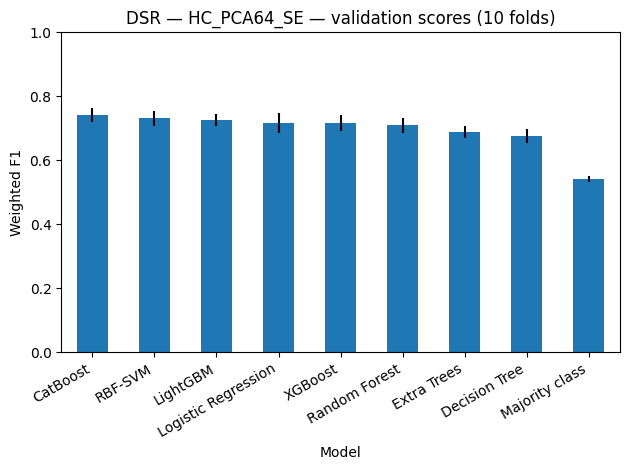

In [ ]:
SEARCHES = {
    "Random Forest": rf_search,
    "LightGBM": lgbm_search,
    "Extra Trees": et_search,
    "RBF-SVM": svm_search,
    "XGBoost": xgb_search,
    "CatBoost": cat_search,
    "Majority class": majority_search,
    "Logistic Regression": logreg_search,
    "Decision Tree": tree_search,
}
ROLES = {"Random Forest": "paper baseline", "LightGBM": "paper baseline",
         "Extra Trees": "proposed", "RBF-SVM": "proposed", "XGBoost": "proposed", "CatBoost": "proposed",
         "Majority class": "reference", "Logistic Regression": "reference", "Decision Tree": "reference"}

def validation_row(name, search):
    assert search.experiment == (TASK, FEATURE_SET, RUN_NAME,)
    results, best = search.cv_results_, search.best_index_
    row = {"Model": name, "Role": ROLES[name]}
    for metric in scoring:
        row[f"CV {metric}"] = results[f"mean_test_{metric}"][best]
    row["CV f1_weighted std"] = results["std_test_f1_weighted"][best]
    return row

comparison = pd.DataFrame(
    [validation_row(name, search) for name, search in SEARCHES.items()]
).sort_values("CV f1_weighted", ascending=False)
comparison.to_csv(OUT / "validation_comparison.csv", index=False)
display(comparison.round(4))

comparison.plot.bar(x="Model", y="CV f1_weighted", yerr="CV f1_weighted std", legend=False, ylim=(0, 1))
plt.title(f"{TASK} — {FEATURE_SET} — validation scores ({len(cv_folds)} folds)")
plt.ylabel("Weighted F1")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
SELECTED_MODEL = comparison.iloc[0]["Model"]
print("Selected model (best mean CV weighted F1):", SELECTED_MODEL)
_ = (OUT / "selected_model.json").write_text(json.dumps({"selected_model": SELECTED_MODEL}, indent=2))

Selected model (best mean CV weighted F1): CatBoost


## 12. Evaluate on the test set

Every model is scored once on the held-out test fields. **The selected model was chosen in section 11 and is not
re-chosen from these numbers**: with about 120 test fields, the 95% bootstrap interval of weighted F1 is several
points wide, wider than most gaps between models.

In [ ]:
actual_test = y_test.to_numpy()
boot_rows = np.random.default_rng(SEED).integers(0, len(actual_test), size=(1000, len(actual_test)))

def test_row(name, search):
    assert search.experiment == (TASK, FEATURE_SET, RUN_NAME,)
    predictions = np.asarray(search.predict(X_test)).reshape(-1)
    pd.DataFrame({"row_position": test_rows,
                  "actual": actual_test,
                  "predicted": predictions,}
    ).to_csv(OUT / f"{name}_test_predictions.csv", index=False)

    boot = [f1_score(actual_test[r], predictions[r], average="weighted", zero_division=0) for r in boot_rows]
    row = {
        "Model": name,
        "Test weighted F1": f1_score(actual_test, predictions, average="weighted", zero_division=0),
        "95% CI": f"{np.percentile(boot, 2.5):.3f}–{np.percentile(boot, 97.5):.3f}",
        "Test macro F1": f1_score(actual_test, predictions, average="macro", zero_division=0),
        "Test accuracy": accuracy_score(actual_test, predictions),
    }
    if TASK != "ALL":
        row[f"Test {POSITIVE_NAME} F1"] = f1_score(actual_test, predictions, pos_label=1, zero_division=0)
        row[f"Test {POSITIVE_NAME} recall"] = recall_score(actual_test, predictions, pos_label=1, zero_division=0)
    return row

if EVALUATE_TEST:
    test_comparison = pd.DataFrame([test_row(name, search) for name, search in SEARCHES.items()])
    test_comparison.insert(1, "Selected in CV", test_comparison["Model"] == SELECTED_MODEL)
    test_comparison.to_csv(OUT / "test_comparison.csv", index=False)
    display(test_comparison.round(4))
else:
    print("Test evaluation skipped. Use the validation table while developing models.")

,Model,Selected in CV,Test weighted F1,95% CI,Test macro F1,Test accuracy,Test DSR F1,Test DSR recall
0,Random Forest,False,0.7499,0.666–0.830,0.7026,0.7642,0.5672,0.475
1,LightGBM,False,0.6866,0.605–0.767,0.6382,0.6911,0.5000,0.475
2,Extra Trees,False,0.6562,0.557–0.744,0.5812,0.6911,0.3667,0.275
3,RBF-SVM,False,0.7120,0.631–0.784,0.6782,0.7073,0.5814,0.625
4,XGBoost,False,0.6944,0.606–0.779,0.6341,0.7154,0.4615,0.375
5,CatBoost,True,0.6696,0.582–0.744,0.6272,0.6667,0.5060,0.525
6,Majority class,False,0.5438,0.432–0.651,0.4029,0.6748,0.0000,0.000
7,Logistic Regression,False,0.6936,0.607–0.772,0.6451,0.6992,0.5067,0.475
8,Decision Tree,False,0.6438,0.558–0.732,0.5807,0.6585,0.4000,0.350


# 13. Evaluation

Sections 11-12 compare all nine models using cross-validation and held-out test metrics. This section takes Random Forest, the paper-baseline model, and CatBoost, the primary proposed model, forward for a closer examination. The analysis compares their per-class performance, confusion matrices, and sample-level classification errors.

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score,
)

# Confirm that both searches belong to the configured experiment.
assert rf_search.experiment == (TASK, FEATURE_SET, RUN_NAME)
assert cat_search.experiment == (TASK, FEATURE_SET, RUN_NAME)

if TASK == "DSR":
    class_labels = [0, 1]
    class_names = ["Not DSR", "DSR"]
elif TASK == "AWD":
    class_labels = [0, 1]
    class_names = ["Not AWD", "AWD"]
else:
    class_labels = [0, 1, 2]
    inverse_label_map = {v: k for k, v in LABEL_MAPS[TASK].items()}
    class_names = [inverse_label_map[i] for i in class_labels]

# Keep predictions aligned to the same held-out test rows.
rf_pred = np.asarray(rf_search.predict(X_test)).reshape(-1)
cat_pred = np.asarray(cat_search.predict(X_test)).reshape(-1)
actual = np.asarray(y_test)
label_names = dict(zip(class_labels, class_names))

print(f"Task: {TASK} | Test samples: {len(y_test)}")


Task: DSR | Test samples: 123


## 13.1 Test performance: Random Forest vs. CatBoost

In [ ]:
rf_report = classification_report(
    y_test, rf_pred, labels=class_labels, target_names=class_names,
    output_dict=True, zero_division=0,
)
cat_report = classification_report(
    y_test, cat_pred, labels=class_labels, target_names=class_names,
    output_dict=True, zero_division=0,
)

performance_comparison = pd.DataFrame({
    "Random Forest": {
        "Test accuracy": accuracy_score(y_test, rf_pred),
        "Weighted F1": f1_score(y_test, rf_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_test, rf_pred, average="macro", zero_division=0),
    },
    "CatBoost": {
        "Test accuracy": accuracy_score(y_test, cat_pred),
        "Weighted F1": f1_score(y_test, cat_pred, average="weighted", zero_division=0),
        "Macro F1": f1_score(y_test, cat_pred, average="macro", zero_division=0),
    },
})
display(performance_comparison.round(4))

print("Per-class metrics — Random Forest")
display(pd.DataFrame(rf_report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(4))
print("Per-class metrics — CatBoost")
display(pd.DataFrame(cat_report).T.loc[class_names, ["precision", "recall", "f1-score", "support"]].round(4))


,Random Forest,CatBoost
Test accuracy,0.7642,0.6667
Weighted F1,0.7499,0.6696
Macro F1,0.7026,0.6272


Per-class metrics — Random Forest


,precision,recall,f1-score,support
Not DSR,0.7812,0.9036,0.8380,83.0
DSR,0.7037,0.4750,0.5672,40.0


Per-class metrics — CatBoost


,precision,recall,f1-score,support
Not DSR,0.7625,0.7349,0.7485,83.0
DSR,0.4884,0.5250,0.5060,40.0


## 13.2 Confusion matrices

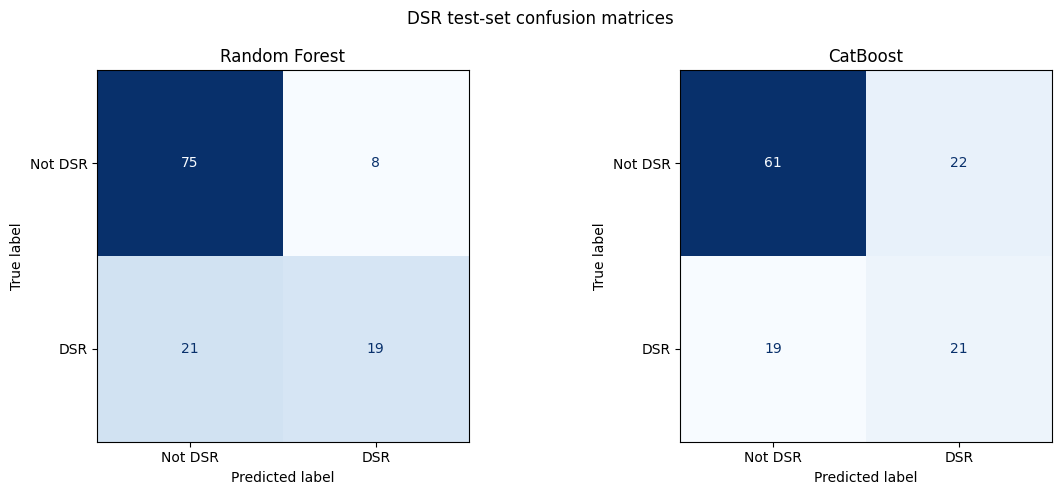

In [ ]:
rf_cm = confusion_matrix(y_test, rf_pred, labels=class_labels)
cat_cm = confusion_matrix(y_test, cat_pred, labels=class_labels)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(rf_cm, display_labels=class_names).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False
)
axes[0].set_title("Random Forest")
ConfusionMatrixDisplay(cat_cm, display_labels=class_names).plot(
    ax=axes[1], cmap="Blues", values_format="d", colorbar=False
)
axes[1].set_title("CatBoost")
fig.suptitle(f"{TASK} test-set confusion matrices")
plt.tight_layout()
plt.show()


The held-out comparison between Random Forest and CatBoost showed that Random Forest achieved better overall classification performance. Random Forest correctly classified 94 of 123 samples (76.42%), compared with 82 samples (66.67%) for CatBoost. Both models correctly classified 80 samples and misclassified 27 samples. However, Random Forest correctly classified 14 samples that CatBoost misclassified, while CatBoost correctly classified only two samples that Random Forest misclassified. The confusion matrices further revealed that CatBoost achieved slightly higher DSR recall (52.50% versus 47.50%), but produced substantially more false positives (22 versus 8), resulting in lower DSR precision (48.84% versus 70.37%). This suggests that CatBoost was more likely to classify samples as DSR, improving its detection of actual DSR samples slightly but increasing incorrect DSR predictions. Overall, Random Forest provided a better balance between identifying DSR and correctly rejecting non-DSR samples under the current experimental setup.

## 13.3 Sample-level error comparison and misclassification analysis

In [ ]:
error_comparison = pd.DataFrame({
    "row_position": np.asarray(test_rows),
    "actual": actual,
    "random_forest_prediction": rf_pred,
    "catboost_prediction": cat_pred,
})

for col in ["actual", "random_forest_prediction", "catboost_prediction"]:
    error_comparison[col] = error_comparison[col].map(label_names)

error_comparison["rf_correct"] = rf_pred == actual
error_comparison["catboost_correct"] = cat_pred == actual
error_comparison["outcome"] = np.select(
    [
        error_comparison["rf_correct"] & error_comparison["catboost_correct"],
        error_comparison["rf_correct"] & ~error_comparison["catboost_correct"],
        ~error_comparison["rf_correct"] & error_comparison["catboost_correct"],
    ],
    ["Both correct", "RF only correct", "CatBoost only correct"],
    default="Both incorrect",
)

print("How the two models performed on the same test samples:")
display(error_comparison["outcome"].value_counts().rename_axis("Outcome").to_frame("Samples"))

print("Misclassified samples:")
display(error_comparison.loc[error_comparison["outcome"] != "Both correct"].head(20))

error_comparison.to_csv(OUT / "rf_vs_catboost_error_comparison.csv", index=False)


How the two models performed on the same test samples:


,Samples
Outcome,
Both correct,80
Both incorrect,27
RF only correct,14
CatBoost only correct,2


Misclassified samples:


,row_position,actual,random_forest_prediction,catboost_prediction,rf_correct,catboost_correct,outcome
3,68,Not DSR,DSR,DSR,False,False,Both incorrect
4,75,Not DSR,Not DSR,DSR,True,False,RF only correct
5,87,Not DSR,DSR,DSR,False,False,Both incorrect
8,117,Not DSR,Not DSR,DSR,True,False,RF only correct
9,127,Not DSR,Not DSR,DSR,True,False,RF only correct
15,177,Not DSR,Not DSR,DSR,True,False,RF only correct
16,186,Not DSR,Not DSR,DSR,True,False,RF only correct
19,216,Not DSR,Not DSR,DSR,True,False,RF only correct
20,228,Not DSR,DSR,DSR,False,False,Both incorrect
22,247,Not DSR,DSR,DSR,False,False,Both incorrect


# 14. Error analysis and feature importance

The paper reports LightGBM gain-based feature importance. Here, Random Forest impurity-based importance and CatBoost's native feature importance are used to identify influential transformed features for each model. These are model-specific importance measures, so their numerical values should not be directly compared. When PCA is included in the feature set, component-level importance should not be interpreted as importance of an individual original input variable.

## 14.1 Random Forest impurity-based feature importance

,feature,importance_mean
127,presto__pca2,0.0364
1,hc_ae__ASCENDING_ratio_gaussian_b,0.0352
6,hc_ae__VV_ASCENDING_mean_spline_troughs_values_3,0.0234
126,presto__pca1,0.0226
20,hc_ae__VH_ASCENDING_mean_spline_troughs_values_3,0.0174
134,presto__pca9,0.0113
19,hc_ae__VH_ASCENDING_mean_spline_troughs_values_2,0.0107
32,hc_ae__ASCENDING_spline_ratio_troughs_values_1,0.0105
33,hc_ae__ASCENDING_spline_ratio_troughs_values_2,0.0099
10,hc_ae__VV_ASCENDING_mean_spline_trough_days_1,0.0093


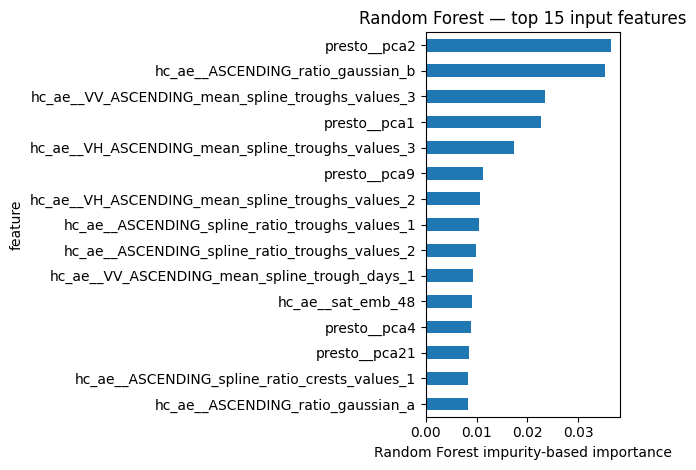

In [ ]:
# Get fitted pipeline and Random Forest
rf_pipeline = rf_search.best_estimator_
rf_model = rf_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps["features"].get_feature_names_out()

# Build importance dataframe
rf_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": rf_model.feature_importances_
}).sort_values("importance_mean", ascending=False)

display(rf_importance_df.head(15).round(4))

rf_importance_df.to_csv(
    OUT / "random_forest_feature_importance.csv",
    index=False
)

# Plot top 15
rf_importance_df.head(15).sort_values("importance_mean").plot.barh(
    x="feature", y="importance_mean", legend=False
)

plt.xlabel("Random Forest impurity-based importance")
plt.title("Random Forest — top 15 input features")
plt.tight_layout()
plt.show()

## 14.2 CatBoost feature importance

,feature,importance
127,presto__pca2,4.7740
1,hc_ae__ASCENDING_ratio_gaussian_b,4.1235
126,presto__pca1,2.7283
6,hc_ae__VV_ASCENDING_mean_spline_troughs_values_3,2.4280
137,presto__pca12,2.1260
85,hc_ae__sat_emb_24,1.8293
156,presto__pca31,1.6216
146,presto__pca21,1.3316
66,hc_ae__sat_emb_5,1.3258
96,hc_ae__sat_emb_35,1.3121


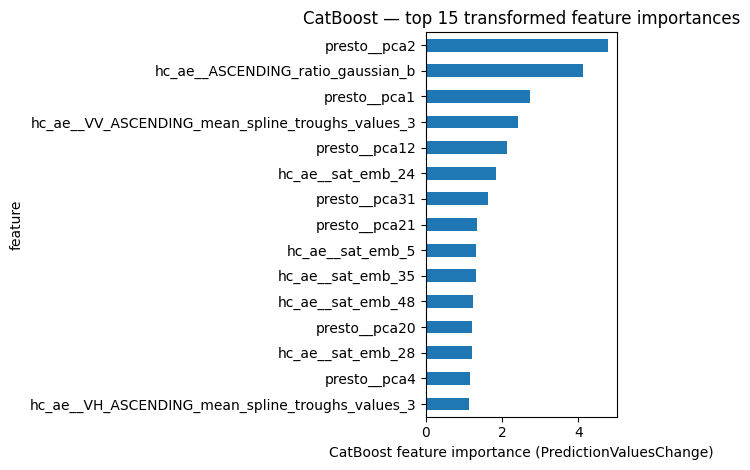

In [ ]:
# Get the fitted CatBoost pipeline and model.
cat_pipeline = cat_search.best_estimator_
cat_model = cat_pipeline.named_steps["model"]

# Get feature names after preprocessing.
cat_feature_names = cat_pipeline.named_steps["features"].get_feature_names_out()

# CatBoost's native PredictionValuesChange feature importance.
cat_importance_df = pd.DataFrame({
    "feature": cat_feature_names,
    "importance": cat_model.feature_importances_,
}).sort_values("importance", ascending=False)

display(cat_importance_df.head(15).round(4))

cat_importance_df.to_csv(
    OUT / "catboost_feature_importance.csv", index=False
)

cat_importance_df.head(15).sort_values("importance").plot.barh(
    x="feature", y="importance", legend=False
)

plt.xlabel("CatBoost feature importance (PredictionValuesChange)")
plt.title("CatBoost — top 15 transformed feature importances")
plt.tight_layout()
plt.show()


## 14.3 Features associated with DSR errors

For the DSR task, compare the transformed feature distributions for correctly and incorrectly classified test fields by CatBoost. This is a descriptive error analysis, not proof that a feature causes misclassification. The analysis focuses on the features ranked highest by CatBoost's native feature importance.

In [ ]:
if TASK == "DSR":
    cat_pipeline = cat_search.best_estimator_

    cat_error_rows = np.flatnonzero(cat_pred != actual)
    cat_correct_rows = np.flatnonzero(cat_pred == actual)

    top_features = cat_importance_df.head(5)["feature"].tolist()

    # Transform test data using the fitted preprocessing pipeline.
    X_test_transformed = cat_pipeline.named_steps["features"].transform(X_test)

    # Get transformed feature names.
    transformed_feature_names = (
        cat_pipeline.named_steps["features"].get_feature_names_out()
    )

    X_test_transformed = pd.DataFrame(
        X_test_transformed,
        columns=transformed_feature_names,
        index=X_test.index
    )

    print("CatBoost test errors:", len(cat_error_rows), "| Correct:", len(cat_correct_rows))

    error_feature_summary = pd.DataFrame({
        "feature": top_features,
        "correct_mean": [
            X_test_transformed.iloc[cat_correct_rows][f].mean()
            for f in top_features
        ],
        "error_mean": [
            X_test_transformed.iloc[cat_error_rows][f].mean()
            for f in top_features
        ],
        "correct_median": [
            X_test_transformed.iloc[cat_correct_rows][f].median()
            for f in top_features
        ],
        "error_median": [
            X_test_transformed.iloc[cat_error_rows][f].median()
            for f in top_features
        ],
    })

    display(error_feature_summary.round(4))

else:
    print("This feature-error comparison is specifically intended for TASK='DSR'.")


CatBoost test errors: 41 | Correct: 82


,feature,correct_mean,error_mean,correct_median,error_median
0,presto__pca2,-1.1921,0.4826,-2.3921,-2.8491
1,hc_ae__ASCENDING_ratio_gaussian_b,27.8330,11.9050,34.5202,27.5246
2,presto__pca1,0.5318,9.0315,5.2682,12.4251
3,hc_ae__VV_ASCENDING_mean_spline_troughs_values_3,23.4512,19.5366,24.0000,20.0000
4,presto__pca12,-1.5986,-1.0372,0.1655,-1.1862


CatBoost produced 41 misclassifications and 82 correct predictions on the held-out test set. Comparing feature distributions between correctly and incorrectly classified samples revealed differences across both Presto components and handcrafted satellite features. The largest mean differences appeared in presto__pca1, presto__pca2, and ASCENDING_ratio_gaussian_b. Misclassified samples had higher average PCA1 and PCA2 values, while their average ASCENDING_ratio_gaussian_b value was substantially lower. These patterns suggest that classification errors are associated with particular regions of the learned feature representation and differences in satellite-derived measurements. However, PCA components do not have direct physical interpretations, and these associations should not be interpreted as causal explanations of model errors.

In [ ]:
# Separate CatBoost DSR false negatives and false positives.
actual_array = np.asarray(actual)
cat_pred_array = np.asarray(cat_pred)

fn_rows = np.flatnonzero((actual_array == 1) & (cat_pred_array == 0))
fp_rows = np.flatnonzero((actual_array == 0) & (cat_pred_array == 1))

print("CatBoost DSR false negatives:", len(fn_rows))
print("CatBoost DSR false positives:", len(fp_rows))


CatBoost DSR false negatives: 19
CatBoost DSR false positives: 22


In [ ]:
# Compare transformed feature values across CatBoost DSR error categories.

groups = {
    "Correct": cat_correct_rows,
    "False Negative": fn_rows,
    "False Positive": fp_rows
}

top_features = cat_importance_df.head(10)["feature"].tolist()

dsr_error_summary = pd.DataFrame([
    {
        "feature": feature,
        **{
            f"{group}_mean": X_test_transformed.iloc[rows][feature].mean()
            for group, rows in groups.items()
        },
        **{
            f"{group}_median": X_test_transformed.iloc[rows][feature].median()
            for group, rows in groups.items()
        }
    }
    for feature in top_features
])

display(dsr_error_summary.round(4))


,feature,Correct_mean,False Negative_mean,False Positive_mean,Correct_median,False Negative_median,False Positive_median
0,presto__pca2,-1.1921,-13.1856,12.2870,-2.3921,-11.8442,16.6089
1,hc_ae__ASCENDING_ratio_gaussian_b,27.8330,29.1054,-2.9498,34.5202,34.2600,20.3959
2,presto__pca1,0.5318,4.2087,13.1966,5.2682,8.2711,14.3962
3,hc_ae__VV_ASCENDING_mean_spline_troughs_values_3,23.4512,22.8947,16.6364,24.0000,24.0000,13.5000
4,presto__pca12,-1.5986,-0.2424,-1.7236,0.1655,0.3906,-2.8820
5,hc_ae__sat_emb_24,0.0385,0.0345,0.0354,0.0414,0.0353,0.0320
6,presto__pca31,0.9382,0.6237,-0.5345,0.5204,0.8928,0.5007
7,presto__pca21,-1.8174,-0.8582,1.4257,-0.9239,-1.7370,-0.2391
8,hc_ae__sat_emb_5,0.0747,0.0760,0.0717,0.0742,0.0741,0.0725
9,hc_ae__sat_emb_35,0.2413,0.2415,0.2378,0.2395,0.2443,0.2344


CatBoost produced 19 false negatives and 22 false positives in the DSR classification task, indicating errors in both identifying actual DSR samples and distinguishing non-DSR samples. Comparing feature distributions across correctly classified samples, false negatives, and false positives revealed distinct error patterns. The clearest difference appeared in the second Presto principal component (PCA2): false negatives had a mean of -13.19, compared with -1.19 for correct predictions, while false positives had a mean of 12.29. False positives also exhibited higher PCA1 values and substantially lower values for the handcrafted ASCENDING_ratio_gaussian_b feature. In contrast, false negatives had relatively similar values for this handcrafted feature compared with correctly classified samples. These results suggest that the two types of classification errors are associated with different regions of the learned feature space and different satellite-derived feature profiles. However, the PCA components are not directly physically interpretable, and these associations do not establish causation.

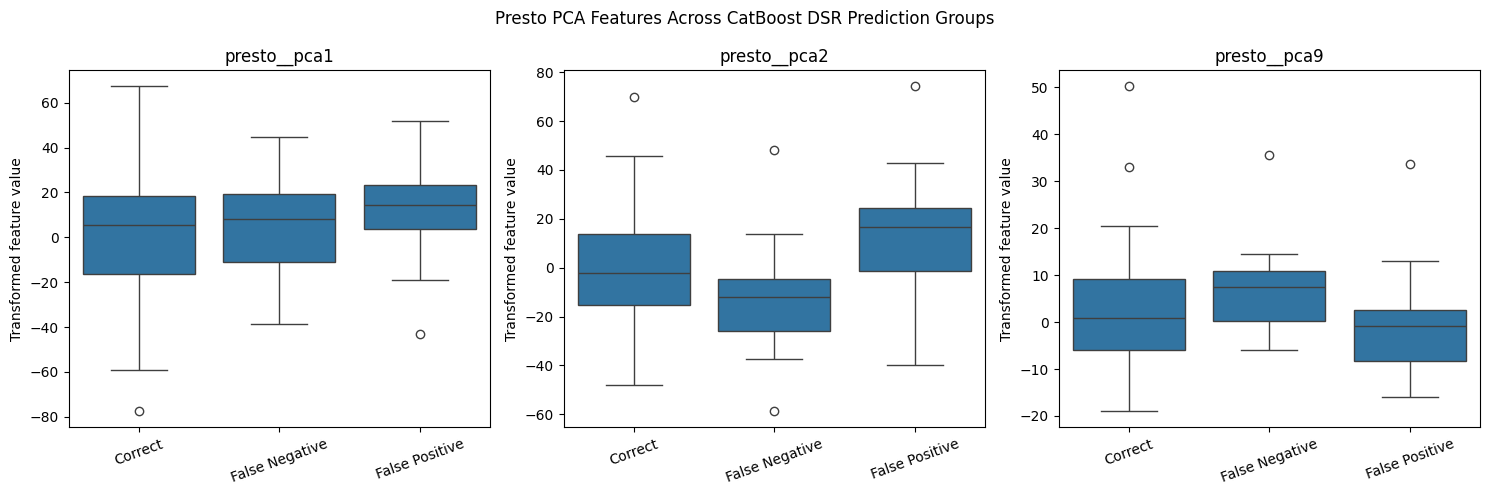

In [ ]:
# Visualize selected Presto PCA components across CatBoost DSR prediction groups.

import matplotlib.pyplot as plt
import seaborn as sns

plot_features = [
    feature for feature in ["presto__pca1", "presto__pca2", "presto__pca9"]
    if feature in X_test_transformed.columns
]

if plot_features and len(fn_rows) and len(fp_rows):
    plot_data = pd.concat([
        X_test_transformed.iloc[cat_correct_rows][plot_features].assign(
            prediction_group="Correct"
        ),
        X_test_transformed.iloc[fn_rows][plot_features].assign(
            prediction_group="False Negative"
        ),
        X_test_transformed.iloc[fp_rows][plot_features].assign(
            prediction_group="False Positive"
        )
    ])

    fig, axes = plt.subplots(1, len(plot_features), figsize=(5 * len(plot_features), 5))
    axes = np.atleast_1d(axes)

    for ax, feature in zip(axes, plot_features):
        sns.boxplot(
            data=plot_data,
            x="prediction_group",
            y=feature,
            order=["Correct", "False Negative", "False Positive"],
            ax=ax
        )
        ax.set_title(feature)
        ax.set_xlabel("")
        ax.set_ylabel("Transformed feature value")
        ax.tick_params(axis="x", rotation=20)

    fig.suptitle("Presto PCA Features Across CatBoost DSR Prediction Groups")
    plt.tight_layout()
    plt.show()
else:
    print("Not plotting: PCA features are unavailable or one DSR error group is empty.")


# 15. Inference

In [ ]:
# Use CatBoost as the primary model for held-out inference.
best_model = cat_search.best_estimator_

# Generate predictions on the held-out test set.
test_predictions = best_model.predict(X_test)
test_predictions = np.asarray(test_predictions).reshape(-1)

# Map encoded labels to readable class names for the configured task.
if TASK == "DSR":
    class_name_map = {0: "Non-DSR", 1: "DSR"}
elif TASK == "AWD":
    class_name_map = {0: "Non-AWD", 1: "AWD"}
else:
    class_name_map = {v: k for k, v in LABEL_MAPS[TASK].items()}

inference_results = pd.DataFrame({
    "true_label": np.asarray(y_test),
    "predicted_label": test_predictions,
    "true_class": pd.Series(np.asarray(y_test), index=X_test.index).map(class_name_map),
    "predicted_class": pd.Series(test_predictions, index=X_test.index).map(class_name_map),
    "correct": np.asarray(y_test) == test_predictions
}, index=X_test.index)

display(inference_results.head(10))

# Save predictions.
inference_results.to_csv(
    OUT / "heldout_inference_predictions.csv",
    index=True
)

print("Inference model: CatBoost")
print("Test samples:", len(inference_results))
print("Correct predictions:", inference_results["correct"].sum())
print("Incorrect predictions:", (~inference_results["correct"]).sum())
print("Held-out accuracy:", round(inference_results["correct"].mean(), 4))


,true_label,predicted_label,true_class,predicted_class,correct
26,0,0,Non-DSR,Non-DSR,True
46,0,0,Non-DSR,Non-DSR,True
55,0,0,Non-DSR,Non-DSR,True
68,0,1,Non-DSR,DSR,False
75,0,1,Non-DSR,DSR,False
87,0,1,Non-DSR,DSR,False
95,0,0,Non-DSR,Non-DSR,True
104,0,0,Non-DSR,Non-DSR,True
117,0,1,Non-DSR,DSR,False
127,0,1,Non-DSR,DSR,False


Inference model: CatBoost
Test samples: 123
Correct predictions: 82
Incorrect predictions: 41
Held-out accuracy: 0.6667


The final inference stage applied the selected CatBoost model to 123 held-out test samples to generate sample-level DSR predictions. The model correctly classified 82 samples and incorrectly classified 41, achieving a held-out accuracy of 66.67%. Each prediction was compared against its ground-truth label to identify correct classifications and errors. The results demonstrate the model's ability to generate predictions on unseen samples, while the error analysis highlights remaining challenges in distinguishing DSR from non-DSR practices. District-level acreage estimates were not generated because the available labeled dataset does not provide the geographic identifiers and field-area information required for spatial aggregation.

# Conclusion
The comparison between CatBoost and Random Forest produced an interesting difference between cross-validation performance and held-out test performance. CatBoost achieved a higher cross-validation weighted F1 score, suggesting stronger average performance across the validation folds. However, Random Forest performed better on the held-out test set, correctly classifying 94 of 123 samples (76.42%), compared with 82 samples (66.67%) for CatBoost.

The difference can be understood by examining the models' classification errors. The dataset contains more non-DSR samples than DSR samples, so weighted F1 gives greater importance to performance on the non-DSR class. CatBoost's higher cross-validation weighted F1 indicates that it performed well on the overall class distribution across the validation folds, but this did not translate into better generalization on the held-out samples. On the test set, CatBoost identified slightly more actual DSR samples than Random Forest, achieving 52.50% DSR recall compared with 47.50%. However, it also produced substantially more false positives (22 compared with 8), reducing its DSR precision to 48.84%, compared with 70.37% for Random Forest.

The sample-level comparison further supports this result. Both models correctly classified 80 samples and misclassified 27, but Random Forest correctly classified 14 samples that CatBoost missed, while CatBoost correctly classified only two samples that Random Forest missed. This indicates that Random Forest was more reliable on the held-out data, particularly when distinguishing non-DSR samples from DSR.

The feature and error analyses provided additional insight into CatBoost's mistakes. Its false negatives and false positives exhibited different patterns across Presto principal components and handcrafted satellite features, suggesting that the two types of errors were associated with different regions of the learned feature space. These patterns help characterize the model's classification difficulties, although they do not establish causal relationships.

Overall, CatBoost's stronger cross-validation weighted F1 score did not translate into superior held-out performance. Random Forest remained the stronger baseline under the final test evaluation, achieving higher accuracy and DSR precision while producing substantially fewer false positives. This demonstrates the importance of evaluating models on an independent test set rather than relying exclusively on cross-validation scores. It also shows that an alternative model can perform competitively during model selection but still generalize less effectively to unseen samples.